<a href="https://colab.research.google.com/github/DrDourado/ME_640_Optimum_Design_Fall_2026/blob/main/ME_640_02_Unconstrained_Examples.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**ME 640 - Optimum Design Methods | Module 1 - Formulation and Computational Foundations**  
**Format:** guided notebook (read -> predict -> run -> interpret -> extend)

## Learning objectives
- Read and modify basic Python expressions, arrays, functions, and plots
- Translate a aircraft wing design, and spring system design into variables, responses, and an objective
- Use a grid search and scipy.optimize to find an optimal solution

## Responsible AI checkpoint
You may use a generative-AI assistant to explain syntax, propose tests, or critique your interpretation. You remain responsible for the formulation, units, constraints, verification, and final engineering claims. Record any material AI assistance in the reflection cell at the end.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import optimize, stats
np.set_printoptions(precision=4, suppress=True)
plt.style.use("seaborn-v0_8-whitegrid")
rng = np.random.default_rng(640)

## Case study: aircraft wing design


*   Goal: minimize required power
*   The power required by an aircraft engine at level flight can be expressed as a ratio between aerodynamic drag and propulsive efficiency: $P=\frac{D v_∞}{η}$

where:


*   $η=η_{max}exp(\frac{-(v_∞-v)^2}{2σ^2})$
*   $L=W_0 + W_s(bc)$
*   $v_∞=\sqrt(\frac{2L}{ρ C_L b c})$
*   $D=\frac{2L^2}{πρ{v_∞}^2 b^2 e}+0.5k(\frac{0.074}{(\frac{ρv_∞c}{μ})^2})ρ{v_∞}^2(2.05bc)$


Use $\rho=1.2$ kg/m³, $\mu=1.8*10^{-5}$ kg/(m sec), $k=1.2$, $c_L=0.4$, $e=0.8$, $W_0=1000$ N, $W_s=8$ N/$m^2$, $η_{max}=1.2$, $v=20$ m/s, and $σ=5$ m/s.

Bounds: $1\le b\le10$ m and $1\le c\le5$ m.

### Functions make the model reusable

In [ ]:
def wing_power(b, c):
    """Inputs b,c in m; returns Power in kJ."""
    rho = 1.2
    mu = 1.8e-5
    k = 1.2
    CL = 0.4
    e = 0.8
    W0 = 1000
    Ws = 8
    eta_max = 1.2
    v = 20
    sigma = 5

    L = W0 + Ws*(b*c)
    v_inf = np.sqrt(2*L/(rho*CL*b*c))
    eta = eta_max*np.exp(-(v**2)/(2*sigma**2))
    D = (2*L**2)/(np.pi*rho*v_inf**2*b**2*e) + 0.5*k*(0.074/(rho*v_inf*c)**2)*(rho*v_inf*c)**2*(2.05*b*c)
    P = D*v_inf/eta
    return P/1000

for c_test in [1, 3, 5]:
    P_test = wing_power(5, c_test)
    print(c_test, "m ->", round(P_test,2), "kJ")

1 m -> 2454.22 kJ
3 m -> 4746.03 kJ
5 m -> 6789.45 kJ


## Grid Search Optimization

The grid search method exhaustively evaluates a range of design parameters (`b` and `c`) to find a solution that satisfies constraints and optimizes the objective function (power).

In [ ]:
# Define the design space for b and c in meters
b_min, b_max = 1, 10
c_min, c_max = 1, 5

# Create a grid of b and c values (e.g., 50 steps for each)
b_vals = np.linspace(b_min, b_max, 50)
c_vals = np.linspace(c_min, c_max, 50)

B, C = np.meshgrid(b_vals, c_vals)

# Calculate responses for each point in the grid
P_grid = wing_power(B, C)

# Find the minimum power among feasible designs
min_power = np.inf
optimal_b, optimal_c = None, None

for i in range(B.shape[0]):
    for j in range(B.shape[1]):
      if P_grid[i, j] < min_power:
        min_power = P_grid[i, j]
        optimal_b = B[i, j]
        optimal_c = C[i, j]

P_grid_opt = wing_power(optimal_b, optimal_c)
print(f" Grid power: {P_grid_opt:.2f} kJ")
print(f" Grid b: {optimal_b:.1f} m")
print(f" Grid c: {optimal_c:.1f} m")

 Grid power: 953.75 kJ
 Grid b: 10.0 m
 Grid c: 1.0 m


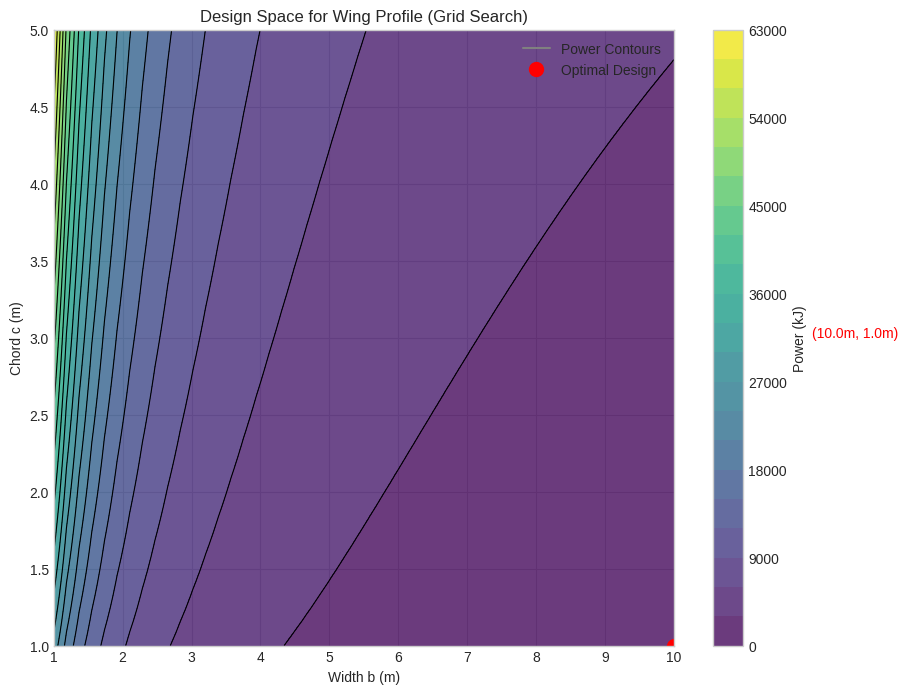

In [ ]:
# Plot the design space and optimal design

fig, ax = plt.subplots(figsize=(10, 8))

contour_power = ax.contourf(B, C, P_grid, levels=20, cmap='viridis', alpha=0.8)
fig.colorbar(contour_power, ax=ax, label='Power (kJ)')

# Add contour lines
ax.contour(B, C, P_grid, levels=20, colors='black', linewidths=0.8)

# Mark the optimal design
if optimal_b is not None and optimal_c is not None:
    ax.plot(optimal_b, optimal_c, 'o', color='red', markersize=10, label='Optimal Design')
    ax.text(optimal_b + 2, optimal_c + 2, f'({optimal_b:.1f}m, {optimal_c:.1f}m)', color='red', fontsize=10)

ax.set_title('Design Space for Wing Profile (Grid Search)')
ax.set_xlabel('Width b (m)')
ax.set_ylabel('Chord c (m)')
ax.set_xlim(b_min, b_max)
ax.set_ylim(c_min, c_max)

# Custom legend handles
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

legend_elements = [
    Line2D([0], [0], color='gray', linestyle='-', label='Power Contours'),
    Line2D([0], [0], marker='o', color='red', label='Optimal Design',
           markerfacecolor='red', markersize=10, linestyle='None')
]

ax.legend(handles=legend_elements, loc='upper right')
ax.grid(True)
plt.show()


## Unconstrained Optimization with SciPy

While a grid search provides a global overview, `scipy.optimize` offers more sophisticated methods to find optimal solutions efficiently. For unconstrained optimization, we'll use `scipy.optimize.minimize` with the `'L-BFGS-B'` method, which is a *quasi-Newton method* that approximates the Broyden–Fletcher–Goldfarb–Shanno (BFGS) algorithm. It is a *gradient-based method*, meaning it uses approximations of the objective function's gradient to determine the search direction. The 'L' stands for 'limited-memory', indicating it stores only a limited number of past updates to approximate the Hessian matrix. It iteratively moves towards the minimum by using gradient information to determine the best direction and step size. When bounds are present, it projects the search steps back onto the feasible region to ensure the design variables remain within their specified limits.

In [ ]:
# Callback function to store optimization path for plotting
optimization_path = []
def callback_func(xk):
    optimization_path.append(xk.copy())

# Initial guess for [b, c] - starting near the center of the design space
initial_guess = [5.5, 3.0]

# Define the bounds for b and c
bounds = [(1, 10), (1, 5)] # (min_b, max_b), (min_c, max_c)

# Perform constrained optimization
result = optimize.minimize(
    lambda x: wing_power(x[0], x[1]), # Objective function, takes [b, c] array
    initial_guess,
    method='L-BFGS-B', # A suitable method for bounded optimization
    bounds=bounds,     # Apply the defined bounds
    callback=callback_func # To record the path for visualization
)

# Extract optimal values from the result
optimal_b_scipy, optimal_c_scipy = result.x
optimal_power_scipy = result.fun

print("\n--- SciPy Optimization Results (L-BFGS-B with Bounds) ---")
print(f"Optimal b: {optimal_b_scipy:.2f} m")
print(f"Optimal c: {optimal_c_scipy:.2f} m")
print(f"Minimum Power: {optimal_power_scipy:.2f} kJ")
print(f"Optimization successful: {result.success}")
print(f"Message: {result.message}")

# Convert optimization path to a NumPy array for easier plotting
optimization_path = np.array(optimization_path)



--- SciPy Optimization Results (L-BFGS-B with Bounds) ---
Optimal b: 10.00 m
Optimal c: 1.00 m
Minimum Power: 953.75 kJ
Optimization successful: True
Message: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL


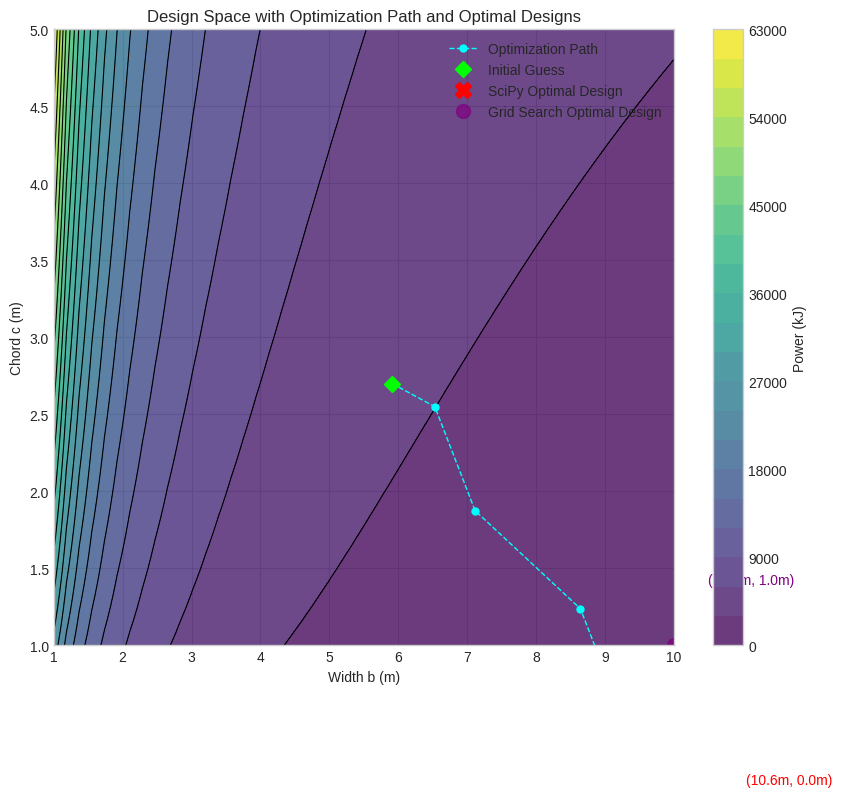

In [ ]:
fig, ax = plt.subplots(figsize=(10, 8))

# Plot the power contours (re-using B, C, P_grid from grid search)
contour_power = ax.contourf(B, C, P_grid, levels=20, cmap='viridis', alpha=0.8)
fig.colorbar(contour_power, ax=ax, label='Power (kJ)')
ax.contour(B, C, P_grid, levels=20, colors='black', linewidths=0.8)

# Plot the optimization path
if len(optimization_path) > 0:
    ax.plot(optimization_path[:, 0], optimization_path[:, 1], 'o--', color='cyan',
            markersize=5, linewidth=1, label='Optimization Path')
    ax.plot(optimization_path[0, 0], optimization_path[0, 1], 'D', color='lime',
            markersize=8, label='Initial Guess')

# Mark the optimal design found by SciPy
ax.plot(optimal_b_scipy, optimal_c_scipy, 'X', color='red', markersize=12, label='SciPy Optimal Design')
ax.text(optimal_b_scipy + 0.5, optimal_c_scipy + 0.1,
        f'({optimal_b_scipy:.1f}m, {optimal_c_scipy:.1f}m)', color='red', fontsize=10)

# Mark the optimal design from Grid Search for comparison
# optimal_b and optimal_c are from the previous grid search result
if optimal_b is not None and optimal_c is not None:
    ax.plot(optimal_b, optimal_c, 'o', color='purple', markersize=10,
            label='Grid Search Optimal Design', alpha=0.7)
    ax.text(optimal_b + 0.5, optimal_c + 0.4,
            f'({optimal_b:.1f}m, {optimal_c:.1f}m)', color='purple', fontsize=10)


ax.set_title('Design Space with Optimization Path and Optimal Designs')
ax.set_xlabel('Width b (m)')
ax.set_ylabel('Chord c (m)')
ax.set_xlim(b_min, b_max)
ax.set_ylim(c_min, c_max)
ax.grid(True)
ax.legend(loc='upper right')
plt.show()

### Explanation of `scipy.optimize.minimize` and L-BFGS-B

`scipy.optimize.minimize` is a general-purpose function in SciPy's optimization module that finds the minimum of a scalar function of one or more variables. It offers various algorithms (methods) to achieve this.

In this case, for *constrained optimization* where we have bounds on our design variables, we used the `'L-BFGS-B'` method:

*   **Method Type:** It is a *quasi-Newton method* that approximates the Broyden–Fletcher–Goldfarb–Shanno (BFGS) algorithm. It is a *gradient-based method*, meaning it uses approximations of the objective function's gradient to determine the search direction. The 'L' stands for 'limited-memory', indicating it stores only a limited number of past updates to approximate the Hessian matrix.
*   **How it works:** It iteratively moves towards the minimum by using gradient information to determine the best direction and step size. When bounds are present, it projects the search steps back onto the feasible region to ensure the design variables remain within their specified limits.
*   **Arguments:**
    *   `fun`: The objective function to be minimized. It must take a 1-D array (`x`) of design variables and return a scalar value.
    *   `x0`: An initial guess for the solution, also as a 1-D array.
    *   `method`: Specifies the algorithm to use (e.g., 'Nelder-Mead', 'BFGS', 'L-BFGS-B', 'SLSQP'). 'L-BFGS-B' is particularly suitable for problems with simple box constraints (bounds).
    *   `bounds`: A sequence of (min, max) pairs for each element in `x`, defining the lower and upper bounds for each design variable.
    *   `callback`: An optional function that is called after each iteration. We used this to record the `xk` (current parameter values) at each step, allowing us to visualize the optimization path.
*   **Advantages:** Efficient for problems with a moderate number of variables and bounds, generally faster convergence than direct search methods like Nelder-Mead for smooth functions, and it respects the specified bounds.
*   **Disadvantages:** Requires gradient information (though it approximates it numerically if not provided analytically), and may get stuck in local minima if the objective function is non-convex.